# Tome 8, Appendix L: Curvature (Python companion)

Exercises first, solutions at the end. We rebuild curves from their curvature, hunt for vertices on random ovals, integrate Gauss curvature over an ellipsoid and a torus, and add up the angle defects of random convex polyhedra. We use `numpy`, `scipy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import math
import numpy as np
from scipy.integrate import cumulative_trapezoid, dblquad
from scipy.spatial import ConvexHull
import matplotlib.pyplot as plt
rng = np.random.default_rng(12)

## Exercises

**P12.1 (★) Curves from curvature.** Using Theorem 12.1, draw the unit-speed curves with $\kappa(s)=1$, $\kappa(s)=s$ (the clothoid of Exercise 12.5), $\kappa(s)=\sin s$ and $\kappa(s)=1+2\cos s$. Check numerically that the clothoid tends to $\bigl(\frac{\sqrt\pi}2,\frac{\sqrt\pi}2\bigr)$.

**P12.2 (★) Total curvature.** Compute $\int\kappa\,ds$ numerically for the circle, the figure eight of Exercise 12.4, and the limaçon $r=\frac12+\cos t$ (which has an inner loop). What multiples of $2\pi$ do you get?

**P12.3 (★★) Four vertices.** Generate random convex ovals $r(t)=1+\sum_{k=2}^{5}(a_k\cos kt+b_k\sin kt)$ with small coefficients, and count the local extrema of the curvature. Theorem 12.2 says at least four. Which counts occur?

**P12.4 (★★) Gauss–Bonnet.** Compute $\iint K\,dA$ for ellipsoids with random semi-axes (Theorem 12.5 predicts $4\pi$) and for a torus (Exercise 12.7).

**P12.5 (★) Descartes' defects.** For random convex polyhedra (convex hulls of random points), add up the angle defects at the vertices and compare with $4\pi$ (Theorem 12.7). Check Euler's formula (Theorem 12.6) on the same polyhedra.

## Solutions

### P12.1
**How to find it.** Integrate twice: $\theta=\int\kappa$, then $\gamma=\int(\cos\theta,\sin\theta)$. A cumulative trapezoid rule on a fine grid does both.

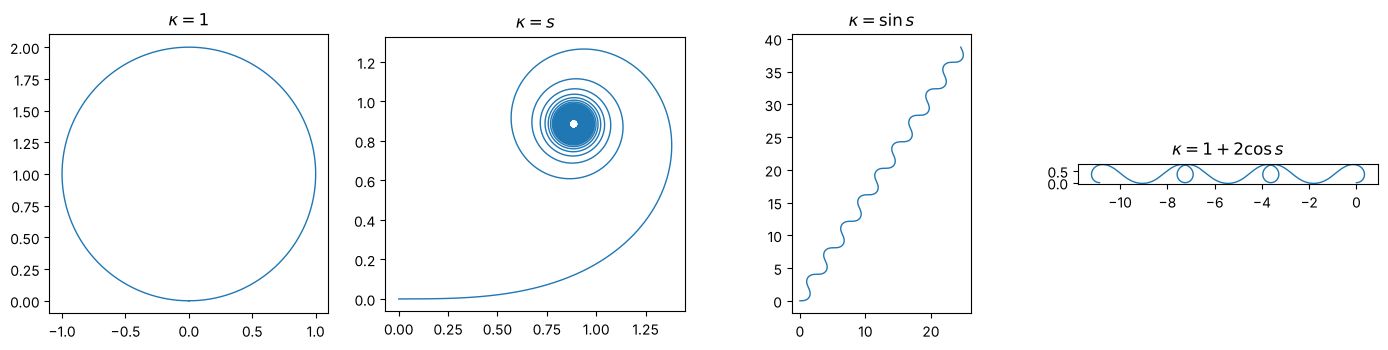

kappa = 1 + 2 cos s: endpoint after one period (-3.6237, -0.0000)


clothoid at s =   10: (0.85903, 0.79002)   limit sqrt(pi)/2 = 0.88623
clothoid at s =   40: (0.90858, 0.89742)   limit sqrt(pi)/2 = 0.88623


clothoid at s =  160: (0.89194, 0.88368)   limit sqrt(pi)/2 = 0.88623


In [2]:
def from_curvature(kappa, L, n=200001):
    s = np.linspace(0, L, n)
    th = cumulative_trapezoid(kappa(s), s, initial=0)
    x = cumulative_trapezoid(np.cos(th), s, initial=0)
    y = cumulative_trapezoid(np.sin(th), s, initial=0)
    return x, y
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6))
cases = [(lambda s: np.ones_like(s), 2 * math.pi, r'$\kappa=1$'), (lambda s: s, 40, r'$\kappa=s$'),
         (np.sin, 60, r'$\kappa=\sin s$'), (lambda s: 1 + 2 * np.cos(s), 6 * math.pi, r'$\kappa=1+2\cos s$')]
for ax, (k, L, t) in zip(axs, cases):
    x, y = from_curvature(k, L)
    ax.plot(x, y, lw=1); ax.set_aspect('equal'); ax.set_title(t)
plt.tight_layout(); plt.show()
x, y = from_curvature(lambda s: 1 + 2 * np.cos(s), 2 * math.pi)
print('kappa = 1 + 2 cos s: endpoint after one period (%.4f, %.4f)' % (x[-1], y[-1]))
for L in [10, 40, 160]:
    x, y = from_curvature(lambda s: s, L, n=2000001)
    print('clothoid at s = %4d: (%.5f, %.5f)   limit sqrt(pi)/2 = %.5f' % (L, x[-1], y[-1], math.sqrt(math.pi) / 2))

The clothoid's distance to its limit point shrinks like $1/s$, so convergence is slow but visible. The curve $\kappa=\sin s$ never closes: its tangent angle $1-\cos s$ oscillates around $1$, so the curve wiggles off in that direction forever. The curve $\kappa=1+2\cos s$ does not close after one period even though $\int_0^{2\pi}\kappa=2\pi$: the endpoint is shifted by $\int_0^{2\pi}e^{i(s+2\sin s)}ds=-2\pi J_1(2)\approx-3.63$ (a Bessel function), so the picture is a chain of loops that drifts along the $x$-axis. Knowing the total turning is not enough to close a curve.

### P12.2
**How to find it.** For a parametrised curve, $\kappa\,ds=\frac{x'y''-y'x''}{x'^2+y'^2}\,dt$, so no arc-length reparametrisation is needed.

In [3]:
def total_curvature(x, y, T=2 * math.pi, n=400001):
    t = np.linspace(0, T, n); h = t[1] - t[0]
    X, Y = x(t), y(t)
    xp, yp = np.gradient(X, h), np.gradient(Y, h)
    xpp, ypp = np.gradient(xp, h), np.gradient(yp, h)
    return np.trapezoid((xp * ypp - yp * xpp) / (xp**2 + yp**2), t)
curves = {'circle': (np.cos, np.sin),
          'figure eight': (lambda t: np.sin(2 * t), np.sin),
          'limacon r = 1/2 + cos t': (lambda t: (.5 + np.cos(t)) * np.cos(t), lambda t: (.5 + np.cos(t)) * np.sin(t))}
for name, (x, y) in curves.items():
    tc = total_curvature(x, y)
    print('%-26s total curvature = %8.5f = %.3f * 2pi' % (name, tc, tc / (2 * math.pi)))

circle                     total curvature =  6.28317 = 1.000 * 2pi
figure eight               total curvature =  0.00000 = 0.000 * 2pi
limacon r = 1/2 + cos t    total curvature = 12.56634 = 2.000 * 2pi


The circle gives $2\pi$, the figure eight $0$ (its two loops cancel, as in the solution of Exercise 12.4), and the limaçon $4\pi$: its tangent turns twice, once for the big loop and once more for the inner one. Only simple closed curves are forced to give $\pm2\pi$.

### P12.3
**How to find it.** For a polar curve, $\kappa=\frac{r^2+2r'^2-rr''}{(r^2+r'^2)^{3/2}}$. Convexity means $\kappa>0$ everywhere. A vertex is a sign change of $\kappa'$ on a fine periodic grid.

In [4]:
def random_oval(scale=0.4):
    k = np.arange(6); w = scale / np.maximum(k, 1) ** 4      # higher harmonics smaller, like a smooth shape
    a, b = rng.normal(0, 1, 6) * w, rng.normal(0, 1, 6) * w
    def r(t, d=0):
        out = np.zeros_like(t) + (1 if d == 0 else 0)
        for k in range(2, 6):
            c, s = a[k] * np.cos(k * t), b[k] * np.sin(k * t)
            if d == 0: out = out + c + s
            elif d == 1: out = out + k * (b[k] * np.cos(k * t) - a[k] * np.sin(k * t))
            else: out = out - k * k * (c + s)
        return out
    return r
t = np.linspace(0, 2 * math.pi, 20000, endpoint=False)
counts = {}
for _ in range(3000):
    r = random_oval()
    r0, r1, r2 = r(t), r(t, 1), r(t, 2)
    kap = (r0**2 + 2 * r1**2 - r0 * r2) / (r0**2 + r1**2) ** 1.5
    if kap.min() <= 0: continue
    dk = np.roll(kap, -1) - kap
    v = int(np.sum(np.sign(dk) != np.sign(np.roll(dk, -1))))
    counts[v] = counts.get(v, 0) + 1
print('number of vertices: how many ovals', dict(sorted(counts.items())))
assert min(counts) >= 4

number of vertices: how many ovals {4: 557, 6: 1580, 8: 774, 10: 89}


Every convex oval has at least four vertices, and the count is always even (maxima and minima of a periodic function alternate). Here the $k$-th harmonic has size about $k^{-4}$, so in the curvature (which feels $r''$) it decays like $k^{-2}$. All even counts from $4$ to $10$ occur, never fewer than four. Ovals that came out non-convex were discarded.

### P12.4
**How to find it.** For the ellipsoid $\frac{x^2}{a^2}+\frac{y^2}{b^2}+\frac{z^2}{c^2}=1$ one has $K=\frac{1}{a^2b^2c^2\,(x^2/a^4+y^2/b^4+z^2/c^4)^2}$. With the parametrisation $(a\sin v\cos u,b\sin v\sin u,c\cos v)$, $dA=\lvert X_u\times X_v\rvert\,du\,dv$.

In [5]:
def ellipsoid_total(a, b, c):
    def f(v, u):
        x, y, z = a * math.sin(v) * math.cos(u), b * math.sin(v) * math.sin(u), c * math.cos(v)
        K = 1 / (a * a * b * b * c * c * (x * x / a**4 + y * y / b**4 + z * z / c**4) ** 2)
        Xu = np.array([-a * math.sin(v) * math.sin(u), b * math.sin(v) * math.cos(u), 0])
        Xv = np.array([a * math.cos(v) * math.cos(u), b * math.cos(v) * math.sin(u), -c * math.sin(v)])
        return K * np.linalg.norm(np.cross(Xu, Xv))
    return dblquad(f, 0, 2 * math.pi, 0, math.pi, epsabs=1e-9)[0]
for _ in range(4):
    a, b, c = rng.uniform(0.3, 3, 3)
    print('ellipsoid %.2f x %.2f x %.2f:  total curvature / 4pi = %.8f' % (a, b, c, ellipsoid_total(a, b, c) / (4 * math.pi)))
Rr, rr = 2.0, 0.7
torus = dblquad(lambda v, u: math.cos(v) / (rr * (Rr + rr * math.cos(v))) * rr * (Rr + rr * math.cos(v)), 0, 2 * math.pi, 0, 2 * math.pi)[0]
print('torus: total curvature = %.2e' % torus)

ellipsoid 2.86 x 0.82 x 1.80:  total curvature / 4pi = 1.00000000


ellipsoid 0.50 x 1.89 x 2.82:  total curvature / 4pi = 1.00000000
ellipsoid 2.74 x 1.66 x 2.70:  total curvature / 4pi = 1.00000000


ellipsoid 2.89 x 2.65 x 1.90:  total curvature / 4pi = 1.00000000
torus: total curvature = 3.29e-15


Every ellipsoid gives $4\pi$ to eight digits, however stretched. The torus gives $0$: the positive curvature on the outside exactly cancels the negative curvature on the inside, since $K\,dA=\cos v\,du\,dv$. This is the beginning of the general Gauss–Bonnet theorem, $\iint K\,dA=2\pi\chi$, with $\chi=2$ for the sphere and $0$ for the torus.

### P12.5
**How to find it.** `ConvexHull` returns triangular facets. The defect at a vertex is $2\pi$ minus the sum of the facet angles there. For Euler's formula, merge coplanar triangles: with random points no four are coplanar, so every facet is a triangle and $F$ is the number of facets.

In [6]:
def angle(p, q, r):
    u, w = q - p, r - p
    return math.acos(np.clip(np.dot(u, w) / np.linalg.norm(u) / np.linalg.norm(w), -1, 1))
for n in [8, 30, 200, 2000]:
    P = rng.normal(size=(n, 3)) * rng.uniform(.3, 2, 3)
    H = ConvexHull(P)
    tot = {}
    for i, j, k in H.simplices:
        for p, q, r in [(i, j, k), (j, k, i), (k, i, j)]:
            tot[p] = tot.get(p, 0) + angle(P[p], P[q], P[r])
    defect = sum(2 * math.pi - s for s in tot.values())
    V, F = len(tot), len(H.simplices)
    E = len({tuple(sorted(e)) for s in H.simplices for e in [(s[0], s[1]), (s[1], s[2]), (s[2], s[0])]})
    print('%5d points: V = %4d, E = %4d, F = %4d, V - E + F = %d, total defect / 4pi = %.12f' % (n, V, E, F, V - E + F, defect / (4 * math.pi)))

    8 points: V =    6, E =   12, F =    8, V - E + F = 2, total defect / 4pi = 1.000000000000
   30 points: V =   14, E =   36, F =   24, V - E + F = 2, total defect / 4pi = 1.000000000000
  200 points: V =   23, E =   63, F =   42, V - E + F = 2, total defect / 4pi = 1.000000000000
 2000 points: V =   41, E =  117, F =   78, V - E + F = 2, total defect / 4pi = 1.000000000000


The total defect is $4\pi$ up to rounding, whether the polyhedron has $6$ vertices or several dozen, and $V-E+F=2$ every time. As the number of points grows, the hull approaches a smooth ellipsoid-like surface and the defects become a discrete version of $K\,dA$: Descartes' theorem is the polyhedral Gauss–Bonnet.